Klasifikasi Plane Kepala Janin (Fetal Head Classification)
- Dataset: Large-Scale Annotation Dataset for Fetal Head Biometry in Ultrasound Images
- Model: ResNet50 Transfer Learning
- Kelas: Transcerebellar, Transthalamic, Transventricular
- XAI: Grad-CAM


In [1]:
import os

input_root = "/kaggle/input"
CLASS_DIRS = set(["Trans-cerebellum", "Trans-thalamic", "Trans-ventricular"])

os.makedirs("outputs", exist_ok=True)  # folder hasil plot (dipakai di cell2)

def is_class_dir(p):
    return all(os.path.isdir(os.path.join(p, c)) for c in CLASS_DIRS)

def print_tree(root, max_depth=6, indent=0):
    """Cetak struktur folder recursive (termasuk symlink), buat diagnosa."""
    try:
        entries = sorted(os.listdir(root))
    except OSError:
        return
    for e in entries:
        sub = os.path.join(root, e)
        if not os.path.isdir(sub):
            continue
        mark = " -> " + os.readlink(sub) if os.path.islink(sub) else "/"
        print("  " * indent + "- " + e + mark)
        if indent < max_depth and not os.path.islink(sub):
            print_tree(sub, max_depth, indent + 1)

def find_dataset(root, max_depth=8):
    """Cari folder berisi 3 kelas USG, rekursif, tahan struktur nested + symlink mount."""
    def walk(p, depth):
        if depth > max_depth:
            return None
        try:
            entries = os.listdir(p)
        except OSError:
            return None
        if p != root and CLASS_DIRS.issubset(entries) and is_class_dir(p):
            return p
        for e in entries:
            sub = os.path.join(p, e)
            if os.path.isdir(sub):
                r = walk(sub, depth + 1)
                if r:
                    return r
        return None
    return walk(root, 0)

BASE = find_dataset(input_root)

if BASE is None:
    print("=" * 70)
    print("ERROR: Dataset tidak ditemukan di /kaggle/input")
    print("Struktur /kaggle/input:")
    print_tree(input_root)
    print("Perbaiki:")
    print("  1. Attach dataset di panel kanan (Add Input) -> pilih 'Fetal Head Ultrasound - Raw Data'")
    print("  2. Dataset harus berisi folder: " + ", ".join(sorted(CLASS_DIRS)))
    print("  3. Lalu Run All lagi")
    print("=" * 70)
    raise SystemExit("Dataset tidak ter-attach. Lihat instruksi di atas.")

print("Dataset root:", BASE)
print("Kelas:", sorted(CLASS_DIRS))

Dataset root: /kaggle/input/datasets/ibnuqayyim/raw-data/raw_data/raw_data
Kelas: ['Trans-cerebellum', 'Trans-thalamic', 'Trans-ventricular']


In [2]:
# Implementasi Grad-CAM lokal, tanpa pip install (Kaggle internet-OFF).
# Deps: torch + cv2 + numpy (semua sudah ada di image base).
import torch

class ClassifierOutputTarget:
    def __init__(self, category):
        self.category = category

class GradCAM:
    def __init__(self, model, target_layers):
        self.model = model
        self.handles = []
        self.gradients = {}
        self.activations = {}
        for name, layer in {f"l{i}": l for i, l in enumerate(target_layers)}.items():
            self.handles.append(layer.register_forward_hook(self._fwd(name)))
            self.handles.append(layer.register_full_backward_hook(self._bwd(name)))

    def _fwd(self, name):
        def hook(m, inp, out):
            self.activations[name] = out
        return hook

    def _bwd(self, name):
        def hook(m, ginp, gout):
            self.gradients[name] = gout[0]
        return hook

    def __call__(self, input_tensor, targets=None):
        self.model.eval()
        output = self.model(input_tensor)
        if targets is not None:
            t = targets[0].category
            score = output[0, t] if output.dim() == 2 else output[0]
        else:
            score = output.flatten().max()
        self.model.zero_grad()
        score.backward(retain_graph=True)
        cam_out = []
        for name in self.activations:
            act = self.activations[name]
            grad = self.gradients[name]
            w = grad.mean(dim=(2, 3), keepdim=True)          # [B, C, 1, 1]
            cam = (w * act).sum(dim=1, keepdim=True)         # [B, 1, H, W]
            cam = torch.relu(cam)
            B, _, H, W = cam.shape
            cam = cam.view(B, H, W)
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-8)
            cam_out.append(cam)
        return torch.stack(cam_out, dim=0).mean(0).detach().cpu().numpy()

def show_cam_on_image(img, mask, use_rgb=True):
    import numpy as np
    import cv2
    # resize mask spatial (misal 7x7) ke ukuran gambar (224x224)
    H, W = img.shape[0], img.shape[1]
    mask = cv2.resize(mask, (W, H))
    if use_rgb:
        heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
        heatmap = np.float32(heatmap) / 255
        cam = heatmap + np.float32(img)
        cam = cam / np.max(cam)
    else:
        heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
        cam = np.float32(heatmap) / 255
    return np.uint8(255 * cam)
print("GradCAM minimal OK (tanpa instal)")

GradCAM minimal OK (tanpa instal)


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
import os, shutil, random

# Cek GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Menggunakan device:", device)

Menggunakan device: cuda


## 1. Persiapan Dataset
Dataset dibagi menjadi train (70%), validasi (15%), dan test (15%)
menggunakan random split dengan seed=42 untuk reprodusibilitas.

In [4]:
import os, shutil, random

def split_dataset(src_dir, dst_dir, class_name):
    images = [f for f in os.listdir(src_dir)
              if f.endswith(('.png', '.jpg', '.jpeg'))]
    random.seed(42)
    random.shuffle(images)

    n = len(images)
    train_end = int(n * 0.70)
    val_end   = int(n * 0.85)

    splits = {
        'train': images[:train_end],
        'val':   images[train_end:val_end],
        'test':  images[val_end:]
    }

    for split, files in splits.items():
        out = os.path.join(dst_dir, split, class_name)
        os.makedirs(out, exist_ok=True)
        for f in files:
            shutil.copy(os.path.join(src_dir, f), out)

    print(f"{class_name}: {len(splits['train'])} train, "
          f"{len(splits['val'])} val, {len(splits['test'])} test")

# Path dataset dari Kaggle input
split_dataset(f"{BASE}/Trans-cerebellum/", "dataset/", "transcerebellar")
split_dataset(f"{BASE}/Trans-thalamic/",   "dataset/", "transthalamic")
split_dataset(f"{BASE}/Trans-ventricular/","dataset/", "transventricular")


transcerebellar: 478 train, 103 val, 103 test
transthalamic: 1095 train, 235 val, 235 test
transventricular: 413 train, 89 val, 89 test


## 2. DataLoader & Augmentasi
Augmentasi diterapkan pada data training (flip, rotasi, color jitter).
WeightedRandomSampler digunakan untuk menangani ketidakseimbangan kelas.

In [5]:
# Hitung jumlah sampel per kelas
train_temp = datasets.ImageFolder("dataset/train")
class_counts = [len(os.listdir(f"dataset/train/{c}"))
                for c in train_temp.classes]
print("Jumlah per kelas:", dict(zip(train_temp.classes, class_counts)))

# Transform
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_data = datasets.ImageFolder("dataset/train", transform=train_transform)
val_data   = datasets.ImageFolder("dataset/val",   transform=val_test_transform)
test_data  = datasets.ImageFolder("dataset/test",  transform=val_test_transform)

# Weighted Sampler
sample_weights = []
for _, label in train_data:
    sample_weights.append(1.0 / class_counts[label])

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(train_data, batch_size=32, sampler=sampler)
val_loader   = DataLoader(val_data,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False)

print("\nKelas      :", train_data.classes)
print("Jumlah train:", len(train_data))
print("Jumlah val  :", len(val_data))
print("Jumlah test :", len(test_data))

Jumlah per kelas: {'transcerebellar': 478, 'transthalamic': 1095, 'transventricular': 413}

Kelas      : ['transcerebellar', 'transthalamic', 'transventricular']
Jumlah train: 1986
Jumlah val  : 427
Jumlah test : 427


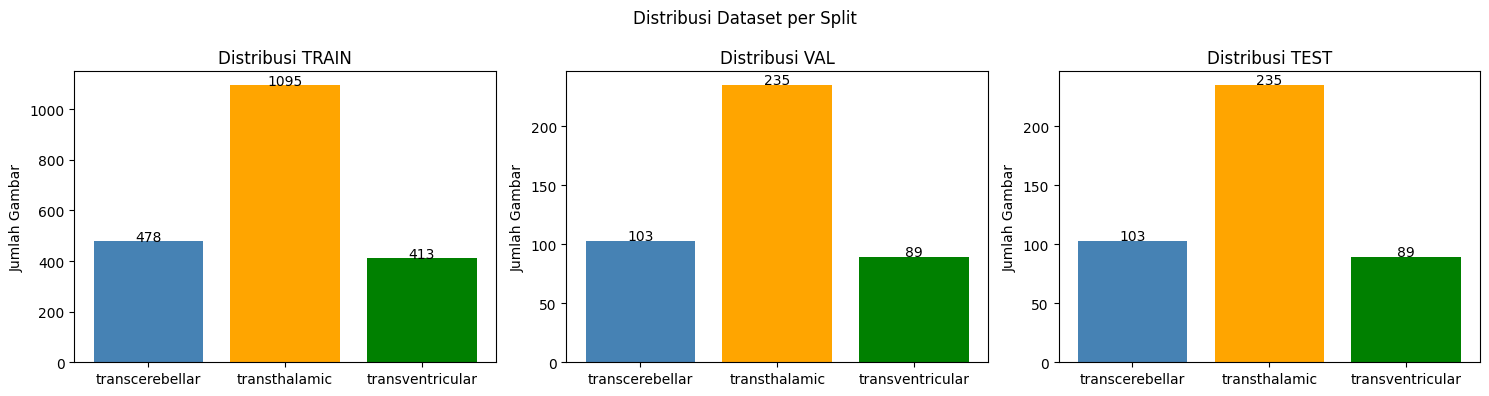

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
splits = ['train', 'val', 'test']

for i, split in enumerate(splits):
    counts = [len(os.listdir(f"dataset/{split}/{c}"))
              for c in train_data.classes]
    axes[i].bar(train_data.classes, counts, color=['steelblue','orange','green'])
    axes[i].set_title(f'Distribusi {split.upper()}')
    axes[i].set_ylabel('Jumlah Gambar')
    for j, v in enumerate(counts):
        axes[i].text(j, v + 1, str(v), ha='center')

plt.suptitle("Distribusi Dataset per Split")
plt.tight_layout()
plt.savefig("outputs/distribusi_dataset.png")
plt.show()

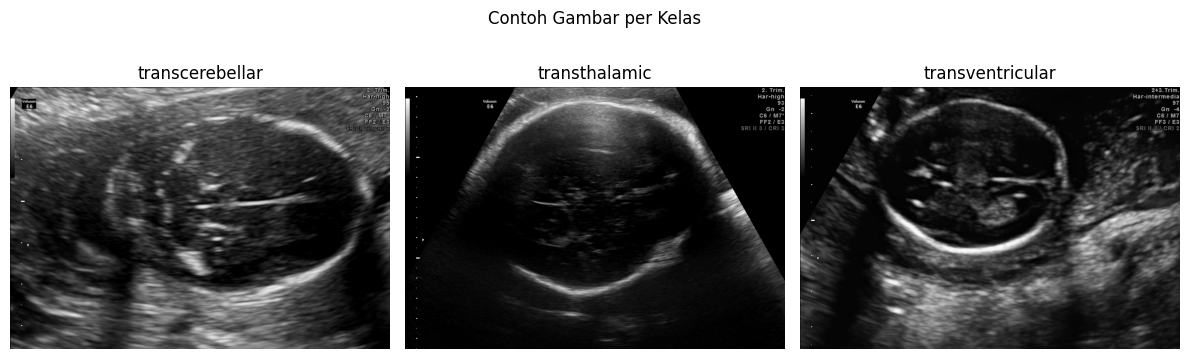

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
class_names = train_data.classes

for i, class_name in enumerate(class_names):
    class_dir = f"dataset/train/{class_name}"
    img_file  = os.listdir(class_dir)[0]
    img       = Image.open(os.path.join(class_dir, img_file))

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(class_name)
    axes[i].axis('off')

plt.suptitle("Contoh Gambar per Kelas")
plt.tight_layout()
plt.show()

## 3. Arsitektur Model
ResNet50 pretrained ImageNet dengan transfer learning.
Layer3 dan Layer4 di-unfreeze untuk fine-tuning.
Custom head dengan Dropout untuk regularisasi.

In [8]:
NUM_CLASSES = 3

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

# Freeze semua layer
for param in model.parameters():
    param.requires_grad = False

# Unfreeze layer3 + layer4
for param in model.layer3.parameters():
    param.requires_grad = True
for param in model.layer4.parameters():
    param.requires_grad = True

# Head lebih dalam
model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(model.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, NUM_CLASSES)
)

model = model.to(device)
print("✅ Model siap!")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 199MB/s]


✅ Model siap!


## 4. Training
- Loss Function: CrossEntropyLoss dengan smoothed class weight
- Optimizer: Adam (lr=1e-4)
- Scheduler: StepLR (step=5, gamma=0.5)
- Early Stopping: patience=7
- Max Epoch: 40

In [9]:
# =============================================
# CLASS WEIGHT (SMOOTHED)
# =============================================
total = sum(class_counts)
class_weights = torch.tensor(
    [total / (len(class_counts) * c) for c in class_counts],
    dtype=torch.float
).to(device)

# Lembutkan weight dengan sqrt agar tidak terlalu ekstrem
class_weights = torch.sqrt(class_weights)
class_weights = class_weights / class_weights.sum()
print("Class weights (smoothed):",
      dict(zip(train_data.classes, class_weights.cpu().numpy())))

# =============================================
# LOSS, OPTIMIZER, SCHEDULER
# =============================================
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

# =============================================
# VARIABEL TRAINING
# =============================================
train_losses, val_losses = [], []
train_accs,   val_accs   = [], []
best_val_acc = 0.0
patience     = 7      # lebih sabar dari sebelumnya
counter      = 0
NUM_EPOCHS   = 40

os.makedirs("outputs", exist_ok=True)

# =============================================
# TRAINING LOOP
# =============================================
for epoch in range(NUM_EPOCHS):
    # --- Training ---
    model.train()
    train_loss, train_correct = 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss    += loss.item()
        train_correct += (outputs.argmax(1) == labels).sum().item()

    # --- Validasi ---
    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss    += criterion(outputs, labels).item()
            val_correct += (outputs.argmax(1) == labels).sum().item()

    # --- Hitung Metrik ---
    t_loss = train_loss / len(train_loader)
    v_loss = val_loss   / len(val_loader)
    t_acc  = train_correct / len(train_data)
    v_acc  = val_correct   / len(val_data)

    train_losses.append(t_loss)
    val_losses.append(v_loss)
    train_accs.append(t_acc)
    val_accs.append(v_acc)

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"Train Loss: {t_loss:.4f} Acc: {t_acc:.4f} | "
          f"Val Loss: {v_loss:.4f} Acc: {v_acc:.4f}")

    # --- Simpan Model Terbaik ---
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        counter = 0
        torch.save(model.state_dict(), "outputs/best_model.pth")
        print(f"  ✅ Model tersimpan (val_acc: {v_acc:.4f})")
    else:
        counter += 1
        print(f"  ⚠️ No improvement ({counter}/{patience})")
        if counter >= patience:
            print(f"\n🛑 Early stopping di epoch {epoch+1}")
            break

    scheduler.step()

print(f"\n🎉 Training selesai!")
print(f"Best Val Accuracy: {best_val_acc:.4f}")

print("✅ Model terbaik tersimpan di outputs/best_model.pth")

Class weights (smoothed): {'transcerebellar': np.float32(0.36542735), 'transthalamic': np.float32(0.24143927), 'transventricular': np.float32(0.3931334)}
Epoch [1/40] Train Loss: 0.7895 Acc: 0.6022 | Val Loss: 0.7523 Acc: 0.6768
  ✅ Model tersimpan (val_acc: 0.6768)
Epoch [2/40] Train Loss: 0.4855 Acc: 0.7966 | Val Loss: 0.8212 Acc: 0.6815
  ✅ Model tersimpan (val_acc: 0.6815)
Epoch [3/40] Train Loss: 0.4485 Acc: 0.8117 | Val Loss: 0.6011 Acc: 0.7611
  ✅ Model tersimpan (val_acc: 0.7611)
Epoch [4/40] Train Loss: 0.3983 Acc: 0.8364 | Val Loss: 0.6280 Acc: 0.7330
  ⚠️ No improvement (1/7)
Epoch [5/40] Train Loss: 0.4200 Acc: 0.8238 | Val Loss: 0.4725 Acc: 0.7986
  ✅ Model tersimpan (val_acc: 0.7986)
Epoch [6/40] Train Loss: 0.3052 Acc: 0.8656 | Val Loss: 0.4274 Acc: 0.8126
  ✅ Model tersimpan (val_acc: 0.8126)
Epoch [7/40] Train Loss: 0.3087 Acc: 0.8666 | Val Loss: 0.4609 Acc: 0.8056
  ⚠️ No improvement (1/7)
Epoch [8/40] Train Loss: 0.2966 Acc: 0.8696 | Val Loss: 0.4999 Acc: 0.8197
  ✅ 

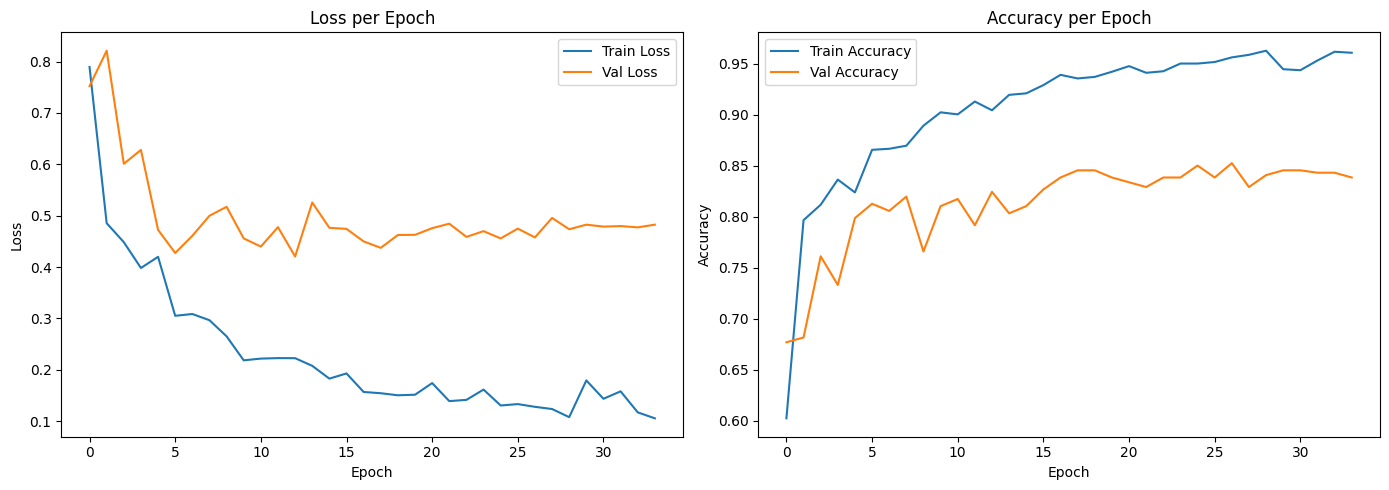

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label='Train Loss')
axes[0].plot(val_losses,   label='Val Loss')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(train_accs, label='Train Accuracy')
axes[1].plot(val_accs,   label='Val Accuracy')
axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/loss_accuracy.png")
plt.show()

In [11]:
model.load_state_dict(torch.load("outputs/best_model.pth"))
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(labels.numpy())

class_names = train_data.classes
print(classification_report(y_true, y_pred, target_names=class_names))

                  precision    recall  f1-score   support

 transcerebellar       0.86      0.91      0.89       103
   transthalamic       0.88      0.81      0.84       235
transventricular       0.70      0.80      0.74        89

        accuracy                           0.83       427
       macro avg       0.81      0.84      0.82       427
    weighted avg       0.84      0.83      0.83       427



## 5. Evaluasi Model
Evaluasi pada test set menggunakan metrik:
Accuracy, Precision, Recall, F1-Score per kelas

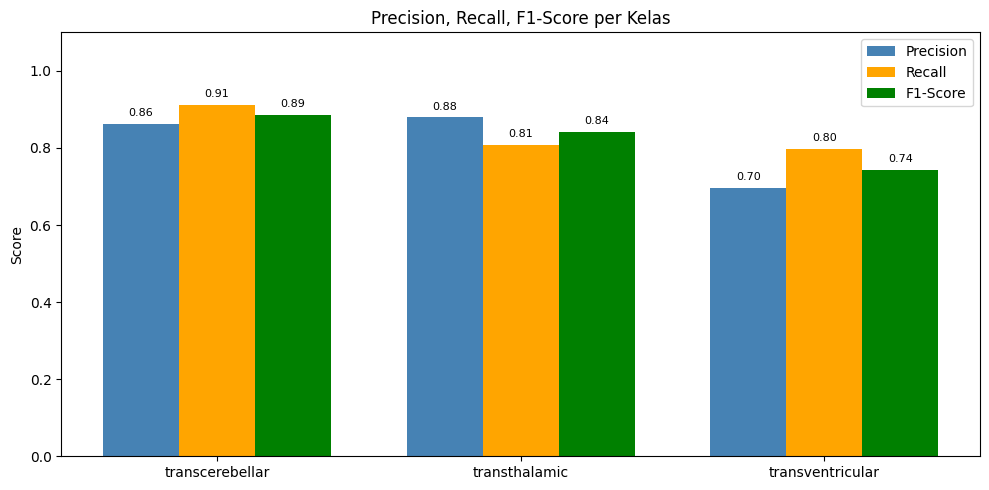

In [12]:
from sklearn.metrics import f1_score, precision_score, recall_score

precision = precision_score(y_true, y_pred, average=None)
recall    = recall_score(y_true, y_pred, average=None)
f1        = f1_score(y_true, y_pred, average=None)

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, precision, width, label='Precision', color='steelblue')
ax.bar(x,         recall,    width, label='Recall',    color='orange')
ax.bar(x + width, f1,        width, label='F1-Score',  color='green')

ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Precision, Recall, F1-Score per Kelas')
ax.legend()

for i in range(len(class_names)):
    ax.text(i - width, precision[i] + 0.02, f'{precision[i]:.2f}', ha='center', fontsize=8)
    ax.text(i,         recall[i]    + 0.02, f'{recall[i]:.2f}',    ha='center', fontsize=8)
    ax.text(i + width, f1[i]        + 0.02, f'{f1[i]:.2f}',        ha='center', fontsize=8)

plt.tight_layout()
plt.savefig("outputs/metrics_per_class.png")
plt.show()

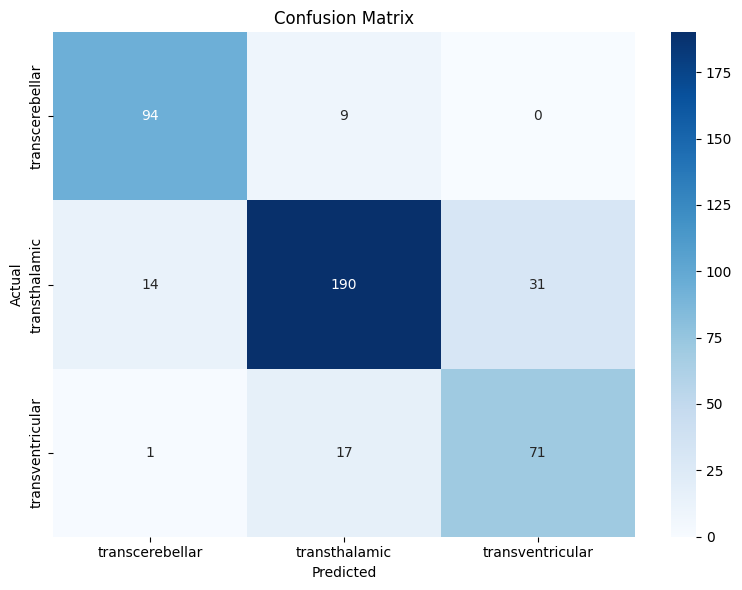

In [13]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png")
plt.show()

## 6. Explainable AI - Grad-CAM
Grad-CAM memvisualisasikan area pada citra USG yang paling
mempengaruhi keputusan prediksi model.

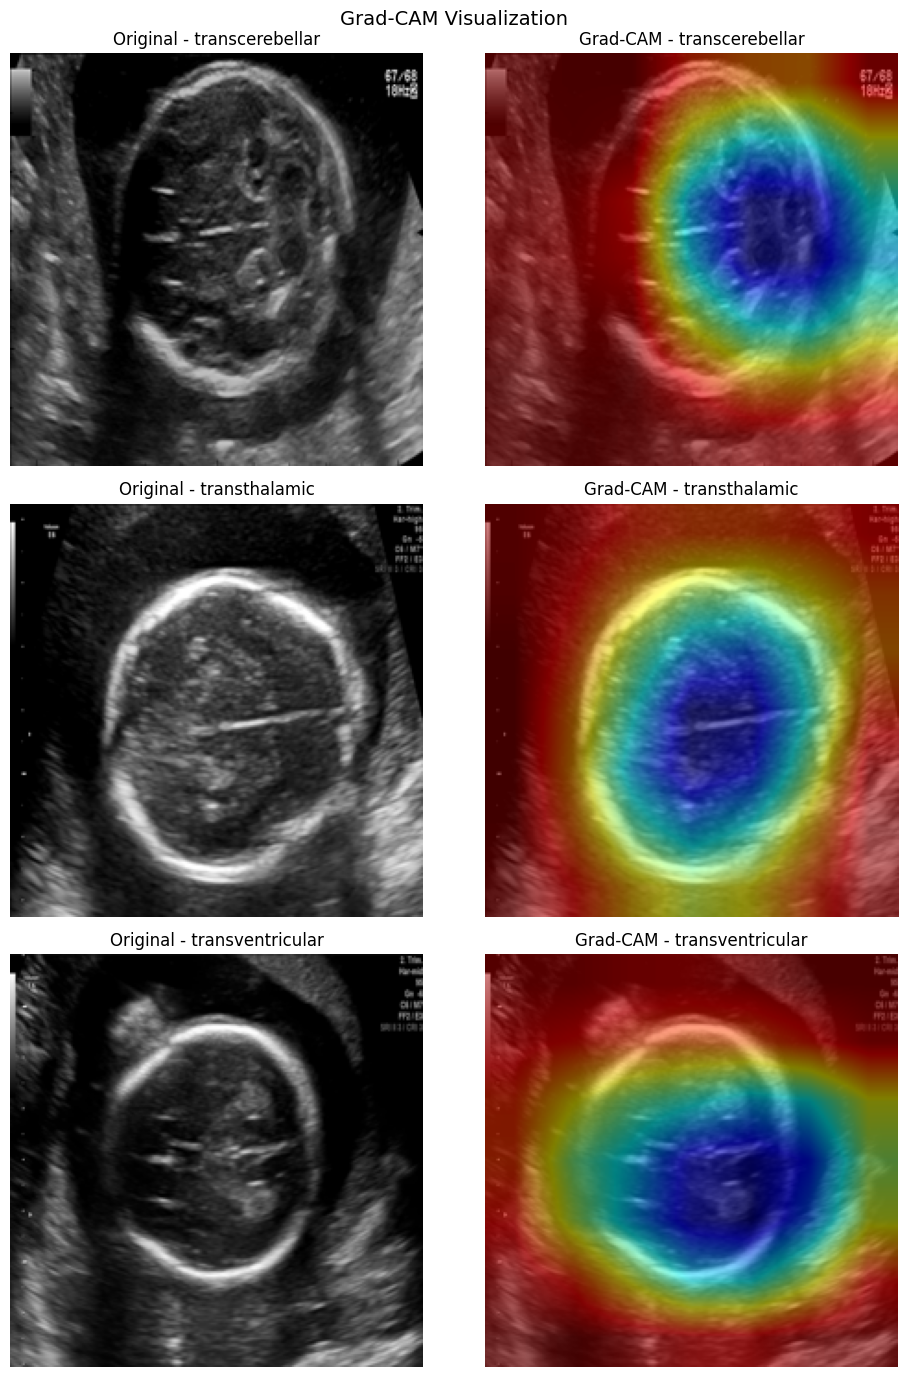

✅ Grad-CAM selesai!


In [14]:
# Grad-CAM menggunakan implementasi lokal (definisi di cell "Grad-CAM minimal").
# class & fungsi: GradCAM, ClassifierOutputTarget, show_cam_on_image — sudah di memory saat cell ini jalan.

target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

fig, axes = plt.subplots(3, 2, figsize=(10, 14))
class_names = train_data.classes

for i, class_name in enumerate(class_names):
    class_dir = f"dataset/test/{class_name}"
    img_file  = os.listdir(class_dir)[0]
    img_path  = os.path.join(class_dir, img_file)

    img_pil = Image.open(img_path).convert("RGB").resize((224, 224))
    img_np  = np.array(img_pil) / 255.0

    input_tensor = val_test_transform(img_pil).unsqueeze(0).to(device)

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(i)]
    )

    visualization = show_cam_on_image(
        img_np.astype(np.float32),
        grayscale_cam[0],
        use_rgb=True
    )

    axes[i][0].imshow(img_np)
    axes[i][0].set_title(f"Original - {class_name}")
    axes[i][0].axis('off')

    axes[i][1].imshow(visualization)
    axes[i][1].set_title(f"Grad-CAM - {class_name}")
    axes[i][1].axis('off')

plt.suptitle("Grad-CAM Visualization", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/gradcam_result.png")
plt.show()
print("✅ Grad-CAM selesai!")